# Part G: Model Evaluation and Comparative Analysis

Evaluate the three selected base models and the final soft-voting ensemble on the **untouched test dataset**. This notebook follows the Part G classification requirements: accuracy, precision, recall, F1, ROC-AUC, confusion matrices, and comparison of performance, generalisation, computational cost, interpretability, and deployment suitability.

**Selected models:** Logistic Regression R3, Random Forest R1, Histogram Gradient Boosting R3. **Final ensemble:** 50% RF R1 + 50% HGB R3, threshold **0.480**.

The test set is used only for final evaluation. No model training, threshold tuning, or selection takes place here.

## 1. Setup and load data

In [1]:
# Import libraries and connect to the existing Google Drive project.
from pathlib import Path
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay)

ROOT = Path('/content/drive/MyDrive/ML_Group')
if not (ROOT / 'test_dataset.csv').is_file():
    drive.mount('/content/drive')

OUT = ROOT / 'Part_G_Results'
OUT.mkdir(parents=True, exist_ok=True)
BASE = ROOT / 'Part_E_Results'

# Data was already preprocessed in earlier parts. Do not preprocess it again.
test_df = pd.read_csv(ROOT / 'test_dataset.csv')
X_test = test_df.drop(columns=['target'])
y_test = test_df['target'].astype(int).to_numpy()
assert set(np.unique(y_test)) == {0, 1}, 'Expected both binary classes in the test set.'
print('Test rows:', len(y_test), '| Features:', X_test.shape[1])
print('Test class counts:', pd.Series(y_test).value_counts().sort_index().to_dict())

Mounted at /content/drive
Test rows: 30655 | Features: 66
Test class counts: {0: 25387, 1: 5268}


## 2. Load selected models and fixed thresholds

Thresholds below are the previously selected Part E values. Check them against your saved Part E records **before the first test run**. The Part F ensemble configuration is loaded from its saved JSON file if present.

In [2]:
# Load fitted models. Do not fit them again.
model_paths = {
    'Logistic Regression': BASE / 'Round_3/saved_models/logistic_regression_round3.joblib',
    'Random Forest': BASE / 'saved_models/random_forest_round1.joblib',
    'Histogram Gradient Boosting': BASE / 'Round_3/saved_models/histogram_gradient_boosting_round3.joblib',
}
for name, path in model_paths.items():
    if not path.is_file():
        raise FileNotFoundError(f'Missing {name}: {path}')
models = {name: joblib.load(path) for name, path in model_paths.items()}

# Fixed base-model thresholds from Part E (not chosen using test data).
thresholds = {
    'Logistic Regression': 0.17623,
    'Random Forest': 0.50300,
    'Histogram Gradient Boosting': 0.42999,
}

# Use the frozen Part F ensemble settings.
config_path = ROOT / 'Part_F_Results/final_ensemble_config.json'
if config_path.is_file():
    config = json.loads(config_path.read_text())
    assert config['model_names'] == ['R1 Random Forest', 'R3 Histogram Gradient Boosting']
    weights = np.asarray(config['weights'], dtype=float)
    ensemble_threshold = float(config['threshold'])
else:
    # Same settings selected in Part F, if its config file was not saved.
    print('Part F config not found; using the agreed frozen settings.')
    weights = np.array([0.5, 0.5])
    ensemble_threshold = 0.480
assert np.allclose(weights, [0.5, 0.5]) and np.isclose(ensemble_threshold, 0.480)
thresholds['Ensemble'] = ensemble_threshold
print('Models loaded:', list(models))
print('Fixed thresholds:', thresholds)
print('Ensemble weights:', weights.tolist())

Models loaded: ['Logistic Regression', 'Random Forest', 'Histogram Gradient Boosting']
Fixed thresholds: {'Logistic Regression': 0.17623, 'Random Forest': 0.503, 'Histogram Gradient Boosting': 0.42999, 'Ensemble': 0.48}
Ensemble weights: [0.5, 0.5]


## 3. Predict and calculate classification metrics

In [3]:
# Keep training feature order and measure the time spent predicting.
def model_input(model, X):
    if hasattr(model, 'feature_names_in_'):
        features = list(model.feature_names_in_)
        missing = sorted(set(features) - set(X.columns))
        if missing:
            raise ValueError(f'Missing features: {missing}')
        return X.loc[:, features]
    return X

def metrics_row(name, y, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        'Model': name, 'Threshold': threshold,
        'Accuracy': accuracy_score(y, pred),
        'Precision': precision_score(y, pred, zero_division=0),
        'Recall': recall_score(y, pred, zero_division=0),
        'F1': f1_score(y, pred, zero_division=0),
        'F2': fbeta_score(y, pred, beta=2, zero_division=0),
        'ROC-AUC': roc_auc_score(y, prob),
        'Average Precision': average_precision_score(y, prob),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }

probabilities, inference_seconds = {}, {}
for name, model in models.items():
    X_input = model_input(model, X_test)
    class_one = list(model.classes_).index(1)
    start = time.perf_counter()
    probabilities[name] = model.predict_proba(X_input)[:, class_one]
    inference_seconds[name] = time.perf_counter() - start

# Soft voting combines the probabilities from the two saved models.
probabilities['Ensemble'] = (
    weights[0] * probabilities['Random Forest'] +
    weights[1] * probabilities['Histogram Gradient Boosting']
)
# Estimated sequential inference time (the component predictions are reused).
inference_seconds['Ensemble'] = (inference_seconds['Random Forest'] +
                                  inference_seconds['Histogram Gradient Boosting'])

results = pd.DataFrame([
    metrics_row(name, y_test, prob, thresholds[name])
    for name, prob in probabilities.items()
])
print('Final test results:')
display(results.round(4))
results.to_csv(OUT / 'model_evaluation_results.csv', index=False)

# Save probability scores and final predicted classes for each model.
preds = pd.DataFrame({'actual': y_test})
for name, prob in probabilities.items():
    preds[f'{name}_prob'] = prob
    preds[f'{name}_pred'] = (prob >= thresholds[name]).astype(int)
preds.to_csv(OUT / 'test_predictions.csv', index=False)

Final test results:


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Average Precision,TN,FP,FN,TP
0,Logistic Regression,0.1762,0.6767,0.2887,0.6023,0.3903,0.4948,0.7034,0.3240,17570,7817,2095,3173
1,Random Forest,0.5030,0.6809,0.2892,0.5875,0.3876,0.4870,0.7040,0.3240,17779,7608,2173,3095
2,Histogram Gradient Boosting,0.4300,0.6640,0.2847,0.6315,0.3925,0.5078,0.7063,0.3249,17027,8360,1941,3327
3,Ensemble,0.4800,0.6899,0.2944,0.5759,0.3896,0.4835,0.7066,0.3271,18116,7271,2234,3034


## 4. Confusion matrices

**False negatives (FN)** are actual charged-off loans predicted as fully paid. **False positives (FP)** are fully paid loans predicted as charged off.

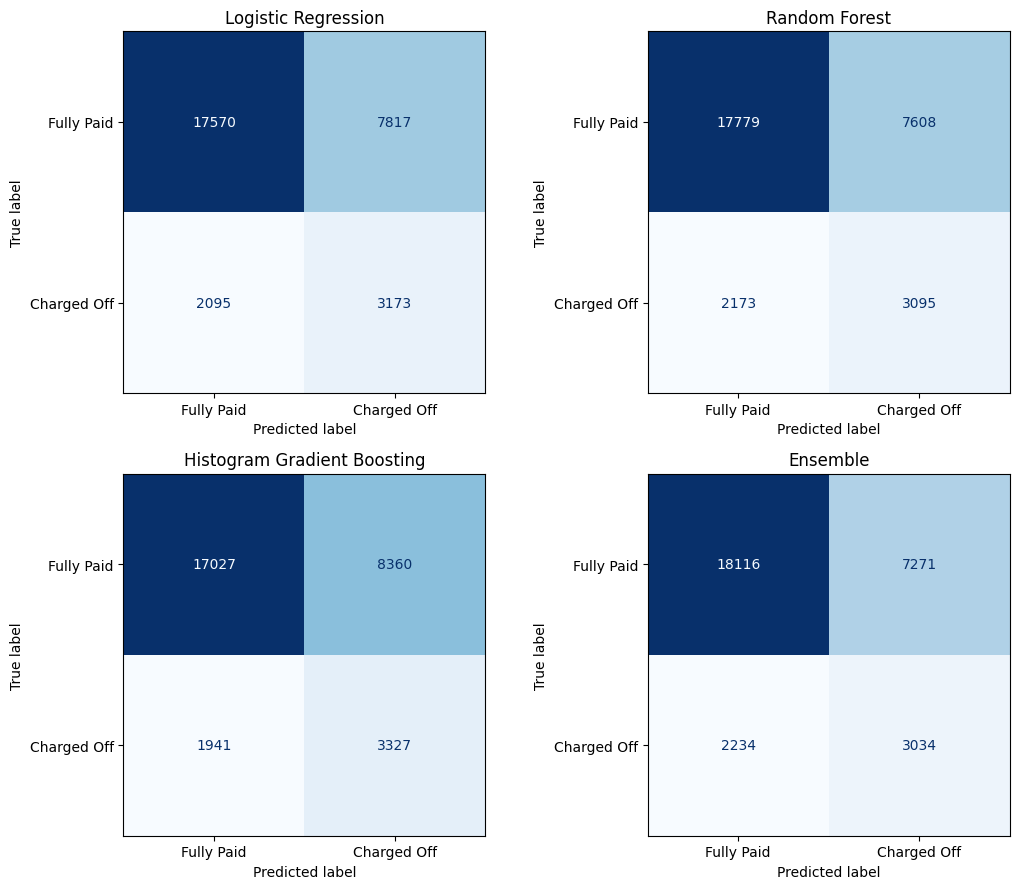

In [4]:
# Show all four confusion matrices with the same class labels.
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, prob) in zip(axes.flat, probabilities.items()):
    pred = (prob >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1],
        display_labels=['Fully Paid', 'Charged Off'],
        cmap='Blues', colorbar=False, values_format='d', ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.savefig(OUT / 'confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

## 5. ROC and precision-recall curves

These curves show model ranking performance across thresholds. The dashed precision-recall reference is the test-set charged-off proportion.

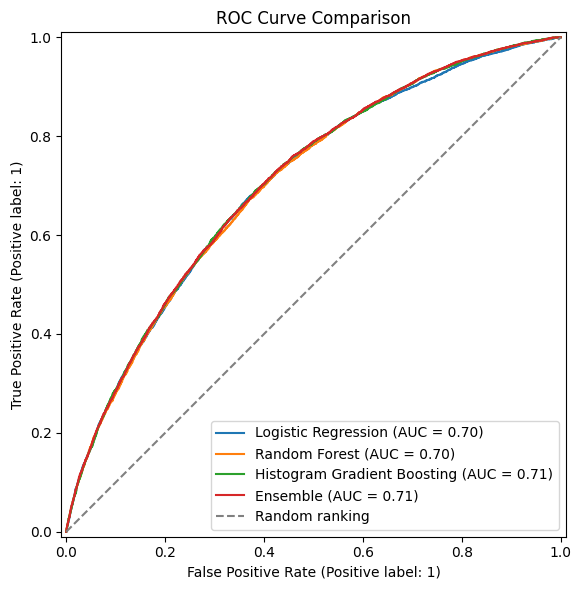

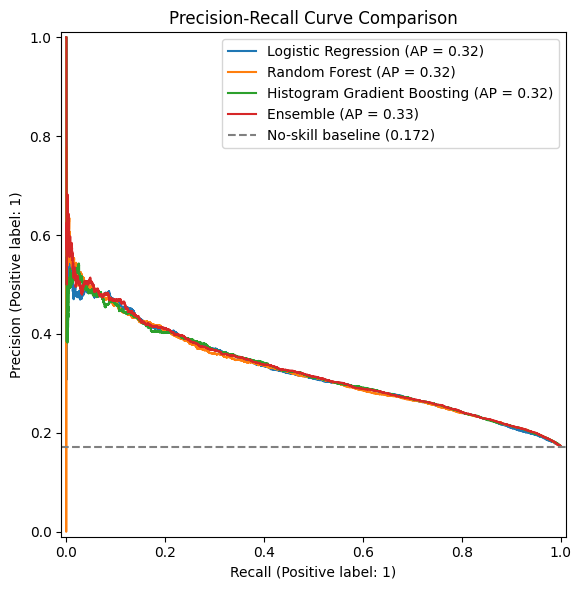

In [5]:
# ROC curves; the diagonal represents random ranking.
fig, ax = plt.subplots(figsize=(8, 6))
for name, prob in probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
ax.set_title('ROC Curve Comparison')
ax.legend()
plt.tight_layout()
plt.savefig(OUT / 'roc_curves.png', dpi=200, bbox_inches='tight')
plt.show()

# Precision-recall curves are useful for the minority Charged Off class.
fig, ax = plt.subplots(figsize=(8, 6))
for name, prob in probabilities.items():
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=ax)
ax.axhline(y_test.mean(), linestyle='--', color='gray',
           label=f'No-skill baseline ({y_test.mean():.3f})')
ax.set_title('Precision-Recall Curve Comparison')
ax.legend()
plt.tight_layout()
plt.savefig(OUT / 'precision_recall_curves.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Compare classification performance

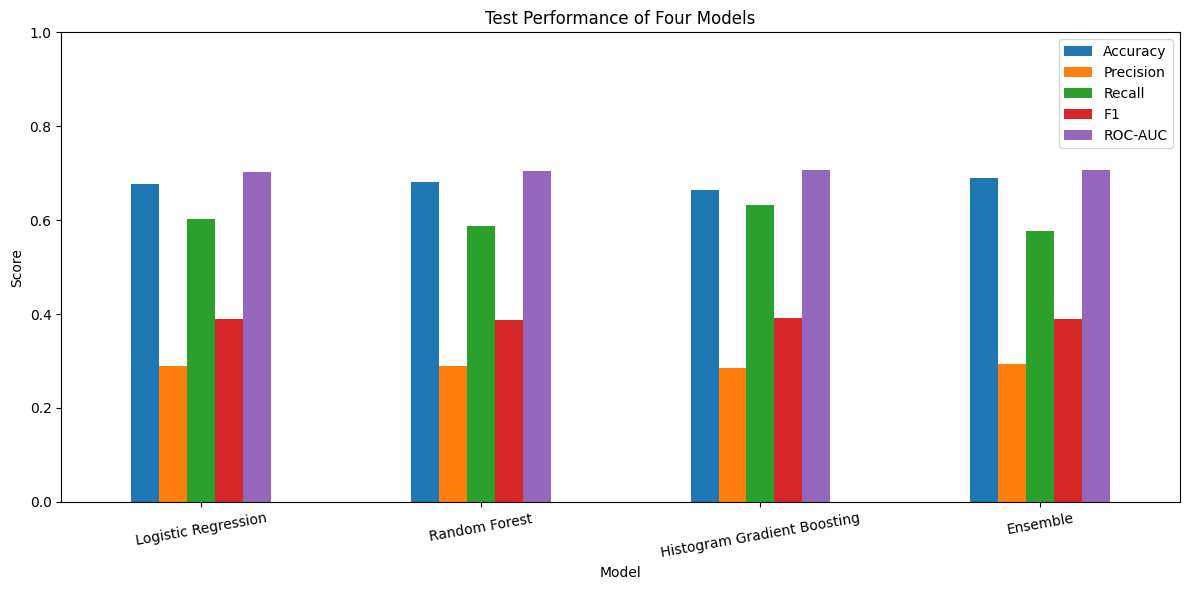

,Model,Accuracy,Precision,Recall,F1,F2,ROC-AUC,FN,FP
0,Logistic Regression,0.6767,0.2887,0.6023,0.3903,0.4948,0.7034,2095,7817
1,Random Forest,0.6809,0.2892,0.5875,0.3876,0.4870,0.7040,2173,7608
2,Histogram Gradient Boosting,0.6640,0.2847,0.6315,0.3925,0.5078,0.7063,1941,8360
3,Ensemble,0.6899,0.2944,0.5759,0.3896,0.4835,0.7066,2234,7271


In [6]:
# Plot the five metrics required by the assignment brief.
main_metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
ax = results.set_index('Model')[main_metrics].plot(kind='bar', figsize=(12, 6), rot=10)
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.set_title('Test Performance of Four Models')
plt.tight_layout()
plt.savefig(OUT / 'performance_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

# Compare how many charge-offs were missed and how many false alarms occurred.
display(results[['Model', 'Accuracy', 'Precision', 'Recall', 'F1',
                 'F2', 'ROC-AUC', 'FN', 'FP']].round(4))

## 7. Computational efficiency and model settings

Prediction time is measured once in this Colab session, so treat it as an approximate comparison. Ensemble time assumes both models run sequentially. Model size is the total size of the saved model files.

In [7]:
# Compare saved file sizes, inference time and selected hyperparameters.
model_size_mb = {
    name: path.stat().st_size / (1024 ** 2)
    for name, path in model_paths.items()
}
model_size_mb['Ensemble'] = (model_size_mb['Random Forest'] +
                             model_size_mb['Histogram Gradient Boosting'])

efficiency = pd.DataFrame([
    {
        'Model': name,
        'Model Size (MB)': model_size_mb[name],
        'Prediction Time (s)': inference_seconds[name],
        'Time per 1000 Samples (ms)': inference_seconds[name] / len(y_test) * 1e6,
    }
    for name in probabilities
])
display(efficiency.round(4))
efficiency.to_csv(OUT / 'computational_efficiency.csv', index=False)

# Record the exact hyperparameters stored in the fitted models.
parameter_names = {
    'Logistic Regression': ['C', 'penalty', 'solver', 'max_iter', 'tol', 'class_weight'],
    'Random Forest': ['n_estimators', 'max_depth', 'min_samples_leaf',
                      'min_samples_split', 'max_features', 'class_weight'],
    'Histogram Gradient Boosting': ['learning_rate', 'max_iter', 'max_leaf_nodes',
                                    'min_samples_leaf', 'l2_regularization',
                                    'early_stopping', 'class_weight'],
}
settings = []
for name, model in models.items():
    params = model.get_params()
    for key in parameter_names[name]:
        settings.append({'Model': name, 'Parameter': key, 'Value': str(params.get(key))})
    if hasattr(model, 'n_iter_'):
        settings.append({'Model': name, 'Parameter': 'Fitted iterations',
                         'Value': str(model.n_iter_)})
settings = pd.DataFrame(settings)
display(settings)
settings.to_csv(OUT / 'selected_model_settings.csv', index=False)

,Model,Model Size (MB),Prediction Time (s),Time per 1000 Samples (ms)
0,Logistic Regression,0.0029,0.0189,0.6169
1,Random Forest,18.9795,0.7548,24.6224
2,Histogram Gradient Boosting,0.3571,0.5992,19.5461
3,Ensemble,19.3366,1.3540,44.1685


,Model,Parameter,Value
0,Logistic Regression,C,0.1
1,Logistic Regression,penalty,l2
2,Logistic Regression,solver,lbfgs
3,Logistic Regression,max_iter,1000
4,Logistic Regression,tol,0.0001
5,Logistic Regression,class_weight,"{0: 1.0, 1: 1.0}"
6,Logistic Regression,Fitted iterations,[37]
7,Random Forest,n_estimators,150
8,Random Forest,max_depth,20
9,Random Forest,min_samples_leaf,50


## 8. Generalisation check (validation vs test)

Compare the same fixed models and thresholds on validation and test. This helps identify possible generalisation gaps. It does **not** replace a training-vs-validation comparison for diagnosing overfitting. The validation dataset is not used to change any model settings.

In [8]:
# Use the already processed validation dataset only for comparison.
validation_path = ROOT / 'validation_dataset.csv'
if validation_path.is_file():
    val_df = pd.read_csv(validation_path)
    X_val = val_df.drop(columns=['target'])
    y_val = val_df['target'].astype(int).to_numpy()
    val_probs = {}
    for name, model in models.items():
        class_one = list(model.classes_).index(1)
        val_probs[name] = model.predict_proba(model_input(model, X_val))[:, class_one]
    val_probs['Ensemble'] = (weights[0] * val_probs['Random Forest'] +
                             weights[1] * val_probs['Histogram Gradient Boosting'])
    val_results = pd.DataFrame([
        metrics_row(name, y_val, prob, thresholds[name])
        for name, prob in val_probs.items()
    ])
    generalisation = val_results[['Model', 'Accuracy', 'Recall', 'F1', 'ROC-AUC']].merge(
        results[['Model', 'Accuracy', 'Recall', 'F1', 'ROC-AUC']],
        on='Model', suffixes=(' Validation', ' Test')
    )
    for metric in ['Accuracy', 'Recall', 'F1', 'ROC-AUC']:
        generalisation[f'{metric} Test - Validation'] = (
            generalisation[f'{metric} Test'] - generalisation[f'{metric} Validation']
        )
    display(generalisation.round(4))
    generalisation.to_csv(OUT / 'validation_test_comparison.csv', index=False)
else:
    print('Validation dataset not found; generalisation comparison skipped.')

,Model,Accuracy Validation,Recall Validation,F1 Validation,ROC-AUC Validation,Accuracy Test,Recall Test,F1 Test,ROC-AUC Test,Accuracy Test - Validation,Recall Test - Validation,F1 Test - Validation,ROC-AUC Test - Validation
0,Logistic Regression,0.6811,0.5761,0.3595,0.6947,0.6767,0.6023,0.3903,0.7034,-0.0045,0.0262,0.0308,0.0087
1,Random Forest,0.6900,0.5761,0.3660,0.6975,0.6809,0.5875,0.3876,0.7040,-0.0091,0.0114,0.0215,0.0064
2,Histogram Gradient Boosting,0.6767,0.5917,0.3625,0.6976,0.6640,0.6315,0.3925,0.7063,-0.0128,0.0398,0.0299,0.0087
3,Ensemble,0.7013,0.5536,0.3654,0.6989,0.6899,0.5759,0.3896,0.7066,-0.0114,0.0223,0.0242,0.0077


## 9. Ensemble differences and uncertainty

The first table shows how much the ensemble differs from each base model. The paired bootstrap estimates a 95% confidence interval for **recall difference** by resampling charged-off test records. This is not a significance test for every metric.

In [9]:
# Positive differences mean the ensemble scored higher than the base model.
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'F2',
                'ROC-AUC', 'Average Precision']
ensemble_row = results.set_index('Model').loc['Ensemble']
comparison_rows = []
for name in models:
    base = results.set_index('Model').loc[name]
    row = {'Compared With': name}
    for metric in metric_names:
        row[f'{metric} Difference'] = ensemble_row[metric] - base[metric]
    row['FN Difference'] = int(ensemble_row['FN'] - base['FN'])
    comparison_rows.append(row)
differences = pd.DataFrame(comparison_rows)
display(differences.round(4))
differences.to_csv(OUT / 'ensemble_vs_base_models.csv', index=False)

# Paired bootstrap: same sampled positive records for both models.
rng = np.random.default_rng(42)
pos_idx = np.flatnonzero(y_test == 1)
ensemble_pred = (probabilities['Ensemble'] >= thresholds['Ensemble']).astype(int)
bootstrap_rows = []
for name in models:
    base_pred = (probabilities[name] >= thresholds[name]).astype(int)
    samples = []
    for _ in range(1000):
        idx = rng.choice(pos_idx, size=len(pos_idx), replace=True)
        samples.append(ensemble_pred[idx].mean() - base_pred[idx].mean())
    lower, upper = np.percentile(samples, [2.5, 97.5])
    bootstrap_rows.append({
        'Compared With': name,
        'Recall Difference': ensemble_pred[pos_idx].mean() - base_pred[pos_idx].mean(),
        '95% CI Lower': lower, '95% CI Upper': upper,
        'CI Excludes Zero': bool(lower > 0 or upper < 0)
    })
bootstrap = pd.DataFrame(bootstrap_rows)
display(bootstrap.round(4))
bootstrap.to_csv(OUT / 'recall_bootstrap_comparison.csv', index=False)

,Compared With,Accuracy Difference,Precision Difference,Recall Difference,F1 Difference,F2 Difference,ROC-AUC Difference,Average Precision Difference,FN Difference
0,Logistic Regression,0.0133,0.0057,-0.0264,-0.0007,-0.0113,0.0032,0.0031,139
1,Random Forest,0.0090,0.0052,-0.0116,0.0021,-0.0035,0.0026,0.0031,61
2,Histogram Gradient Boosting,0.0260,0.0097,-0.0556,-0.0028,-0.0243,0.0003,0.0022,293


,Compared With,Recall Difference,95% CI Lower,95% CI Upper,CI Excludes Zero
0,Logistic Regression,-0.0264,-0.0342,-0.0188,True
1,Random Forest,-0.0116,-0.0165,-0.0063,True
2,Histogram Gradient Boosting,-0.0556,-0.0617,-0.0492,True


## 10. Interpretability, deployment, and final summary

Interpretability and deployment notes are qualitative. Use the measured test performance and efficiency tables to support the final recommendation in the report. **Do not revise the models or thresholds based on these test results.**

In [10]:
# Qualitative notes to support the written comparison.
notes = pd.DataFrame([
    {'Model': 'Logistic Regression', 'Interpretability': 'Higher',
     'Deployment Notes': 'Single linear model; coefficients can be inspected; generally lightweight.'},
    {'Model': 'Random Forest', 'Interpretability': 'Lower',
     'Deployment Notes': 'Many decision trees; larger model may increase memory and inference cost.'},
    {'Model': 'Histogram Gradient Boosting', 'Interpretability': 'Lower',
     'Deployment Notes': 'Nonlinear model; prediction explanations may require additional tools.'},
    {'Model': 'Ensemble', 'Interpretability': 'Lower',
     'Deployment Notes': 'Requires both RF and HGB; extra storage and maintenance.'},
])
display(notes)
notes.to_csv(OUT / 'interpretability_deployment_notes.csv', index=False)

# Report metric leaders without treating them as a new tuning decision.
summary_lines = ['PART G: FINAL TEST EVALUATION', '']
for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'F2',
               'ROC-AUC', 'Average Precision']:
    best = results.loc[results[metric].idxmax()]
    line = f'Highest {metric}: {best["Model"]} ({best[metric]:.4f})'
    print(line)
    summary_lines.append(line)

fewest_fn = results.loc[results['FN'].idxmin()]
line = f'Fewest missed charge-offs: {fewest_fn["Model"]} ({int(fewest_fn["FN"])} FN)'
print(line)
summary_lines.append(line)
summary_lines += ['', 'Model settings were fixed before test evaluation.',
                  'Interpret results alongside false positives, inference cost and interpretability.']
(OUT / 'final_evaluation_summary.txt').write_text('\n'.join(summary_lines))
print('\nAll outputs saved to:', OUT)

,Model,Interpretability,Deployment Notes
0,Logistic Regression,Higher,Single linear model; coefficients can be inspe...
1,Random Forest,Lower,Many decision trees; larger model may increase...
2,Histogram Gradient Boosting,Lower,Nonlinear model; prediction explanations may r...
3,Ensemble,Lower,Requires both RF and HGB; extra storage and ma...


Highest Accuracy: Ensemble (0.6899)
Highest Precision: Ensemble (0.2944)
Highest Recall: Histogram Gradient Boosting (0.6315)
Highest F1: Histogram Gradient Boosting (0.3925)
Highest F2: Histogram Gradient Boosting (0.5078)
Highest ROC-AUC: Ensemble (0.7066)
Highest Average Precision: Ensemble (0.3271)
Fewest missed charge-offs: Histogram Gradient Boosting (1941 FN)

All outputs saved to: /content/drive/MyDrive/ML_Group/Part_G_Results
